In [1]:
import matplotlib.pyplot as plt
import numpy as np
from adjoint import *

font = {"size": 26}
plt.rc("font", **font)
plt.rcParams["figure.figsize"] = (16, 9)
plt.rcParams["lines.linewidth"] = 5

In [2]:
f_targ = 0.05  # focal length of lens
ell = 0  # order of Bessel J function
# Beam Parameters
wl = 1e-6
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
fn = 25  # f#
w0 = f_targ / (2 * fn)  # initial spot size
rmax = 5 * w0  # the max value of r
nr = 1000  # number of points in r
zR = np.pi * w0**2 / wl  # Initial rayleigh length
wR = 2 / np.pi * fn * wl  # Diffraction limited spot size

# Distance parameters
dz = 2e-2
nzf = 1000
zF = np.linspace(f_targ - dz, f_targ + dz, nzf)
fl = len(zF) // 2  # focal length index

print(rmax/nr < wR)

True


In [3]:
[r, k] = DHTarrays(nr, rmax, ell)
[T_R2K, T_K2R] = DHTtransformMatrix(nr, rmax, ell)

rho = r / rmax
Z_fit = calc_Z(rho)

In [4]:
rmax

0.005

In [5]:
rmax**2 / (4*f_targ)*0.5

6.25e-05

In [6]:
k0*1e-10

0.0006283185307179587

In [7]:
phi_I = 1j * np.exp(-((r / w0) ** 2))
z0=[-2,0,1]
# z0=[-1e6,0.5,1e6]

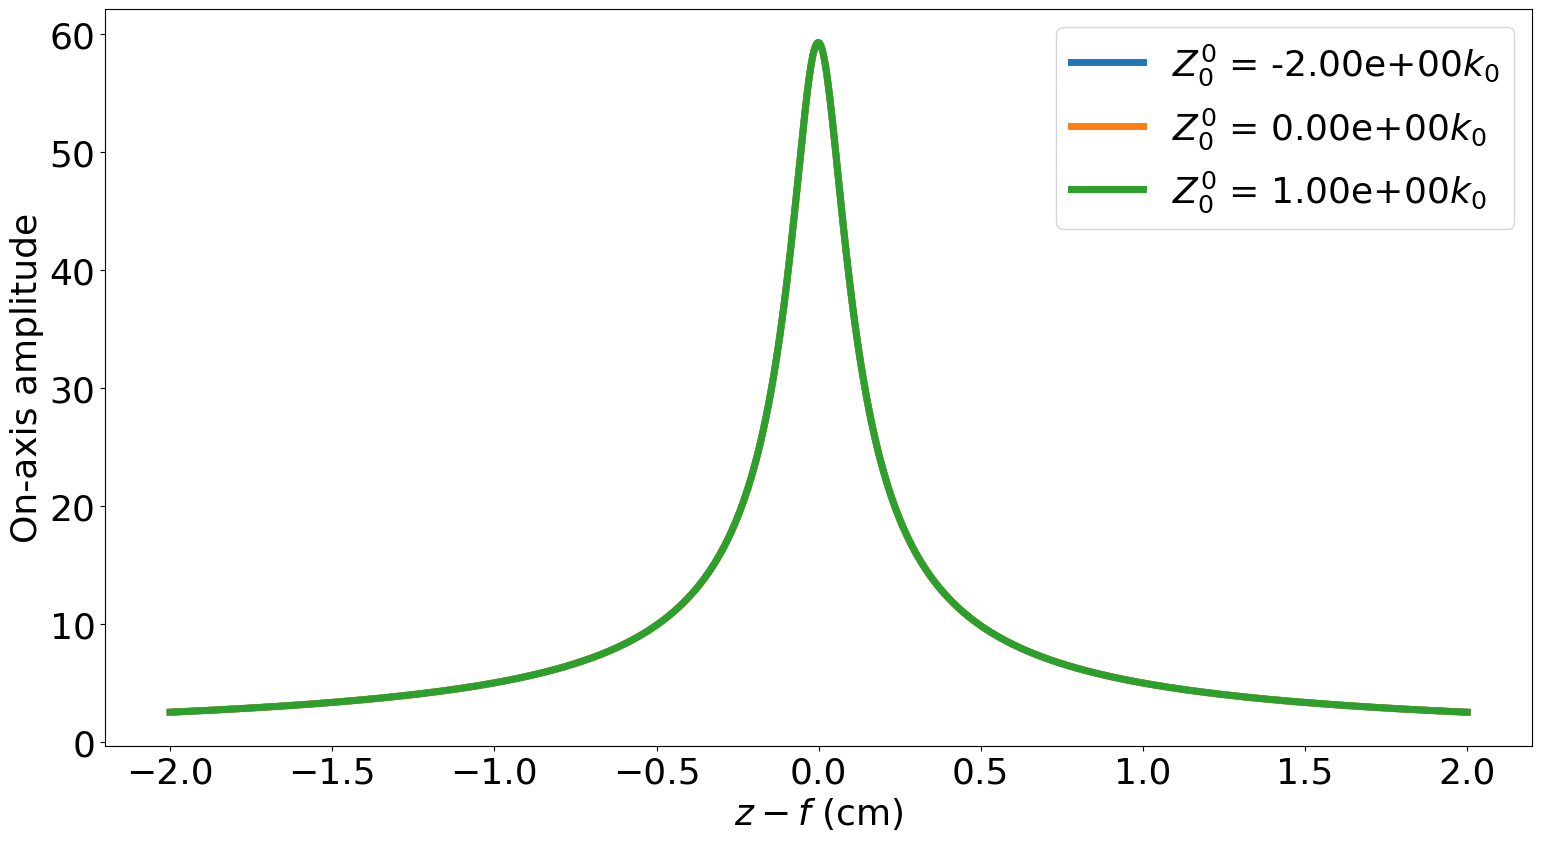

In [8]:
for dz in z0:
    a_n=rmax**2 / (4*f_targ) * np.array([dz*k0, 1 / (2 * np.sqrt(3))])
    zm=generate_optic(a_n, Z_fit)

    ftf=forward_propagation(k, phi_I, T_R2K, T_K2R, zF, zm, wl)

    plt.plot((zF - f_targ) * 100 , np.abs(ftf[0, :]), label=r"$Z_0^0$ = %.2e$k_0$" % dz)

plt.xlabel(r"$z-f$ (cm)")
plt.ylabel("On-axis amplitude")
plt.legend()
plt.tight_layout()
plt.savefig("piston_shift.png")